# Report figures
Rebuilds the README figures from files in `results/`. No training happens here.

## Figure 4: how much of the teacher's gain a small model keeps
From `results/distill_summary.csv` (paired bootstrap over the test rows, 1,000 draws).

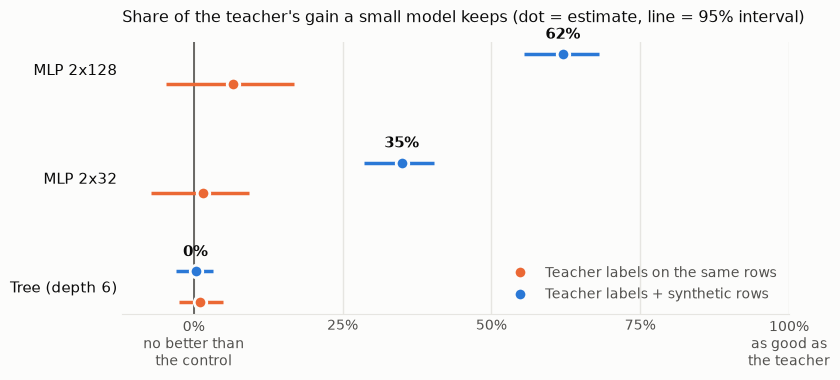

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib import RESULTS_DIR

effects = pd.read_csv(RESULTS_DIR / "distill_summary.csv")
students = ["MLP 2x128", "MLP 2x32", "Tree (depth 6)"]  # strongest first, top to bottom
series = [  # (effect name in the table, legend label, colour slot, vertical offset)
    ("teacher labels (arm 2 vs. 1)", "Teacher labels on the same rows", "#eb6834", 0.14),
    ("both (arm 3 vs. 1)", "Teacher labels + synthetic rows", "#2a78d6", -0.14),
]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

fig, ax = plt.subplots(figsize=(8.5, 3.9), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for effect, label, color, dy in series:
    d = effects[effects["effect"] == effect].set_index("student").loc[students]
    y = [i + dy for i in range(len(students))]
    x = d["share_of_teacher_gain"] * 100
    ax.hlines(y, d["share_lo"] * 100, d["share_hi"] * 100, color=color, lw=2.5, zorder=3)
    ax.plot(x, y, "o", color=color, ms=9, mec="#fcfcfb", mew=2, label=label, zorder=4)
    if "synthetic" in label:  # label the headline numbers only
        for xi, yi in zip(x, y, strict=True):
            ax.annotate(f"{xi:.0f}%", (xi, yi), xytext=(0, 11), textcoords="offset points",
                        ha="center", fontsize=11, fontweight="bold", color=INK)

ax.axvline(0, color=MUTED, lw=1.2, zorder=2)
ax.set_yticks(range(len(students)), students, fontsize=11, color=INK)
ax.invert_yaxis()
ax.set_xlim(-12, 100)
ax.set_xticks([0, 25, 50, 75, 100], ["0%\nno better than\nthe control", "25%", "50%", "75%", "100%\nas good as\nthe teacher"], fontsize=10, color=MUTED)
ax.grid(axis="x", color=GRID, lw=1, zorder=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(length=0)
ax.set_title("Share of the teacher's gain a small model keeps (dot = estimate, line = 95% interval)",
             loc="left", fontsize=11.5, color=INK, pad=14)
ax.legend(loc="lower right", frameon=False, fontsize=10, labelcolor=MUTED)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig4_distillation.png", dpi=170, facecolor=fig.get_facecolor())
plt.show()